# CLUSTERING

As part of the exercise, experiments will be carried out on both artificial and real data. The following functions are suitable for generating artificial data:

* `make_classification` - generates a given number of points (`n_samples`) belonging to a predefined number of classes (`n_classes`) in a feature space with a given number of dimensions (`n_features`) 

http://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_classification.html

* `make_blobs` - generates a given number of normally distributed clusters (`centers`) containing a given number of points (`n_samples`) in a space with a given number of dimensions (`n_features`) 

http://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_blobs.html#sklearn.datasets.make_blobs

In [37]:
from sklearn.datasets import load_iris
from sklearn.datasets import make_blobs, make_classification
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import time
import pandas as pd

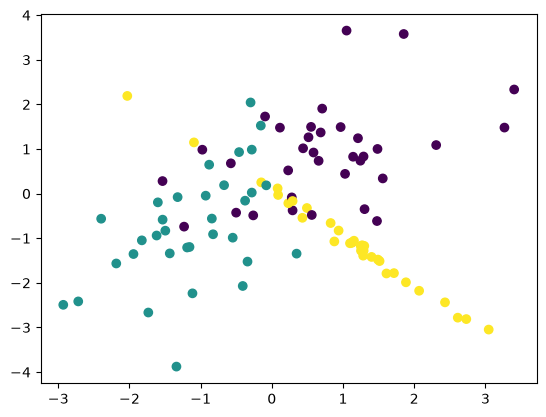

In [38]:
#x, y = make_blobs(n_features=2, centers=5)
x, y =  make_classification(n_features=2, n_redundant=0, n_informative=2, n_clusters_per_class=1, n_classes=3)
plt.scatter(x[:,0],x[:,1], c=y)
plt.show()

# k-means algorithm

The `KMeans` function groups the data into a given number of clusters (`n_clusters`). The algorithm is run a given number of times (parameter `n_init`, default 10) for different initial locations of cluster centers. Finally, the best solution is selected, i.e. the one for which the average distance of points from cluster centers is the smallest. The `get_params` attribute contains the method parameters. 

http://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html

In [39]:
k_means = KMeans(n_clusters=3)
print(k_means.get_params)
t0 = time.time()
k_means.fit(x)
print("Training time: ", time.time() - t0)

<bound method BaseEstimator.get_params of KMeans(n_clusters=3)>
Training time:  0.0020034313201904297


The final position of cluster centers may be read form `cluster_centers_` attribute.

In [40]:
k_means.cluster_centers_

array([[ 1.42817808, -1.41139942],
       [ 0.44663932,  0.95527877],
       [-1.36906665, -1.18740121]])

After clustering, any data point can be assigned to the closest cluster using the `predict` method. 

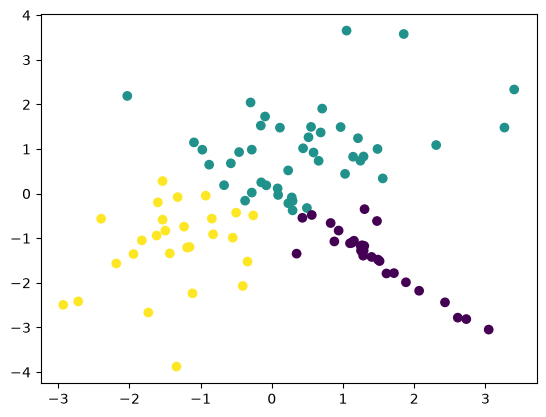

In [41]:
y_predict = k_means.predict(x)
plt.scatter(x[:,0],x[:,1],c = y_predict)
plt.show()

**Exercise 1**

Perform k-means clustering for the generated data set, determining in advance the number of clusters for each data set. Without changing the number of clusters, experiment with different values of the input parameters, which you can read about in the documentation. Investigate which of the input parameters of the method can positively affect the efficiency of the algorithm, both in terms of clustering quality and speed. As a measure of clustering quality, take the `inertia_` attribute, which is the sum of the squared distances of sample points from the cluster centers (the smaller the value, the better). As a measure of speed take the `n_iter` attribute which is the number of iterations performed. The results of the experiments should be visible, i.e. do not print the final conclusion only, but also the results leading to the conclusions. 

In [42]:
configs = [
    {"name": "Domyślna (k-means++, n_init=10)", "init": "k-means++", "n_init": 10, "algorithm": "lloyd", "tol": 1e-4},
    {"name": "Losowa inicjalizacja (random, n_init=10)", "init": "random", "n_init": 10, "algorithm": "lloyd", "tol": 1e-4},
    {"name": "Pojedynczy start (k-means++, n_init=1)", "init": "k-means++", "n_init": 1, "algorithm": "lloyd", "tol": 1e-4},
    {"name": "Pojedynczy start losowy (random, n_init=1)", "init": "random", "n_init": 1, "algorithm": "lloyd", "tol": 1e-4},
    {"name": "Duże n_init (n_init=25)", "init": "k-means++", "n_init": 25, "algorithm": "lloyd", "tol": 1e-4},
    {"name": "Algorytm Elkan", "init": "k-means++", "n_init": 10, "algorithm": "elkan", "tol": 1e-4},
    {"name": "Wysoka tolerancja (tol=1e-2)", "init": "k-means++", "n_init": 10, "algorithm": "lloyd", "tol": 1e-2},
    {"name": "Niska tolerancja (tol=1e-6)", "init": "k-means++", "n_init": 10, "algorithm": "lloyd", "tol": 1e-6},
]

results = []

for config in configs:
    km = KMeans(
        n_clusters=3,
        init=config['init'],
        n_init=config['n_init'],
        algorithm=config['algorithm'],
        tol=config['tol']
    )

    time_start = time.time()
    km.fit(x)
    time_end = time.time()

    duration = time_end - time_start

    results.append({
        'configuration': config['name'],
        "init": config["init"],
        "n_init": config["n_init"],
        "algorithm": config["algorithm"],
        "tol": config["tol"],
        'inertia': km.inertia_,
        'number_of_iterations': km.n_iter_,
        'duration': duration
    })

df_results = pd.DataFrame(results).sort_values(['inertia', 'number_of_iterations', 'duration'])
display(df_results)

,configuration,init,n_init,algorithm,tol,inertia,number_of_iterations,duration
2,"Pojedynczy start (k-means++, n_init=1)",k-means++,1,lloyd,0.000100,144.688149,4,0.001000
7,Niska tolerancja (tol=1e-6),k-means++,10,lloyd,0.000001,144.688149,4,0.016623
5,Algorytm Elkan,k-means++,10,elkan,0.000100,144.688149,4,0.019855
4,Duże n_init (n_init=25),k-means++,25,lloyd,0.000100,144.688149,5,0.037675
3,"Pojedynczy start losowy (random, n_init=1)",random,1,lloyd,0.000100,144.688149,6,0.002153
0,"Domyślna (k-means++, n_init=10)",k-means++,10,lloyd,0.000100,144.688149,6,0.018713
1,"Losowa inicjalizacja (random, n_init=10)",random,10,lloyd,0.000100,144.688149,8,0.015336
6,Wysoka tolerancja (tol=1e-2),k-means++,10,lloyd,0.010000,144.809391,4,0.013891


**Evaluating the quality of clustering**

There are some cluster validity indices.
1. If some labels are given (e.g. class assignements), you may apply Adjusted Round Index (ARI) (`sklearn.metrics.adjusted_rand_score`) taking values from [-1, 1].
2. if class assigment is not known (which is usually the case while performing clustering), you may apply silhouette coefficient (`sklearn.metrics.silhouette_score`) taking values from [-1, 1].

The description of all measures may be found at
http://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation

In [43]:
from sklearn import metrics
print("The value of ARI: ",metrics.adjusted_rand_score(y, y_predict)) 
print("The value of SILHOUETTE coefficient: ",metrics.silhouette_score(x, y_predict, metric='euclidean')) 

The value of ARI:  0.3811649441568561
The value of SILHOUETTE coefficient:  0.43661420653052324


**Excersise 2**

For the generated data set, plot a graph showing the relationship between the values of silhouette coefficient and the number of detected clusters. 

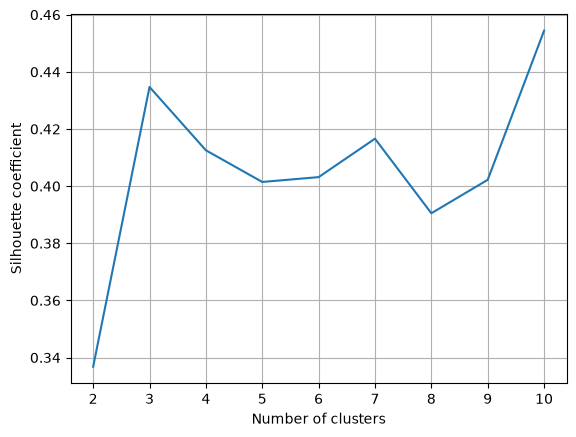

,Number of clusters,Silhouette coefficient
0,2,0.336807
1,3,0.434721
2,4,0.412545
3,5,0.401468
4,6,0.403157
5,7,0.416607
6,8,0.390516
7,9,0.402217
8,10,0.454406


In [44]:
k_values = range(2,11)

results = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=1)
    km.fit(x)
    labels = km.predict(x)
    score = metrics.silhouette_score(x, labels, metric='euclidean')
    results.append(score)

plt.plot(k_values, results)
plt.xlabel('Number of clusters')
plt.ylabel("Silhouette coefficient")
plt.grid()
plt.show()

df = pd.DataFrame({
    'Number of clusters': k_values,
    'Silhouette coefficient': results
})
display(df)

# Hierarchical clustering

The first experiments will be performed on the `digits` dataset. In order to be able to demonstrate the clustering results on a 2D plot, the `digits` data will first be transformed into two-dimensional space. 

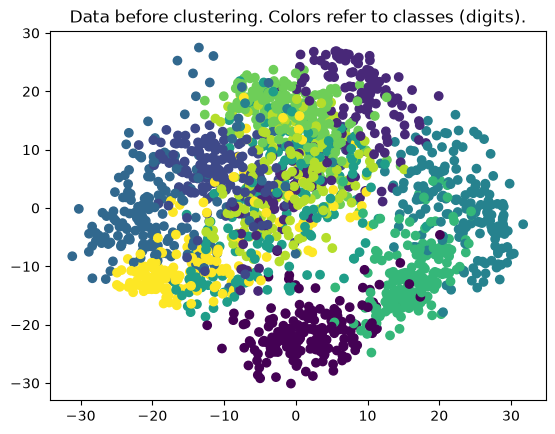

In [45]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
digits = load_digits(n_class=10)
X = digits.data
y = digits.target
n_samples, n_features = X.shape
X_2D = PCA(n_components=2).fit_transform(X) #transforming multidimensional data to 2D
plt.title("Data before clustering. Colors refer to classes (digits).")
plt.scatter(X_2D[:,0], X_2D[:,1],c=y)
plt.show()

Hierarchical clustering may be performed using `AgglomerativeClustering` function.

http://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html


Parameter `linkage` defines the way a distance between clusters is calculated. It can be as follows:
* `ward` - minimizing variance of the clusters;
* `average` - average distance between pairs of points from two clusters;
* `complete` - maximum distance between pairs of points from two clusters;
* `single` - minimum distance between pairs of points from two clusters.

See below how the method works for `digits` data for the above four cases. 


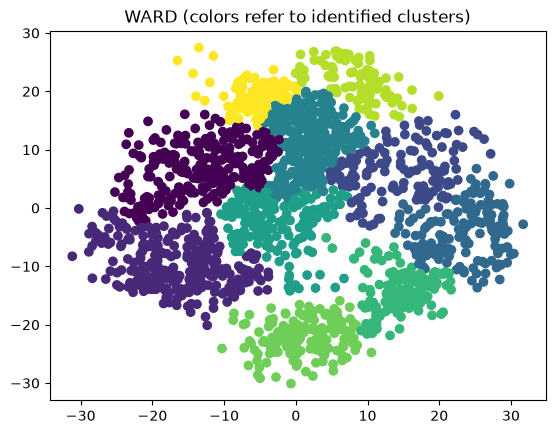

In [46]:
h = AgglomerativeClustering(linkage='ward', n_clusters=10)
h.fit(X_2D)
plt.title("WARD (colors refer to identified clusters)")
plt.scatter(X_2D[:,0], X_2D[:,1],c=h.labels_)
plt.show()

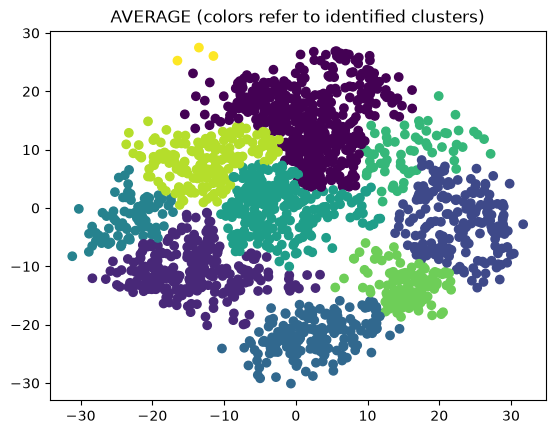

In [47]:
h = AgglomerativeClustering(linkage='average', n_clusters=10)
h.fit(X_2D)
plt.title("AVERAGE (colors refer to identified clusters)")
plt.scatter(X_2D[:,0], X_2D[:,1],c=h.labels_)
plt.show()

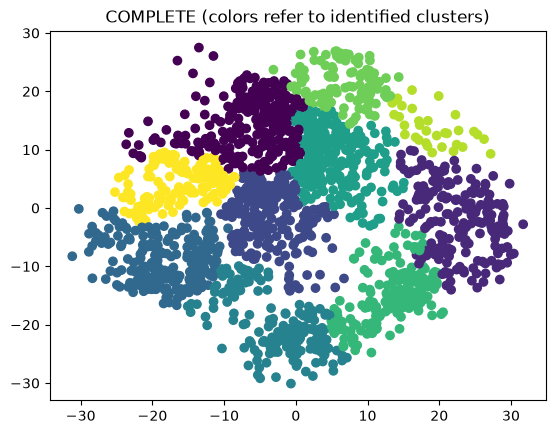

In [48]:
h = AgglomerativeClustering(linkage='complete', n_clusters=10)
h.fit(X_2D)
plt.title("COMPLETE (colors refer to identified clusters)")
plt.scatter(X_2D[:,0], X_2D[:,1],c=h.labels_)
plt.show()

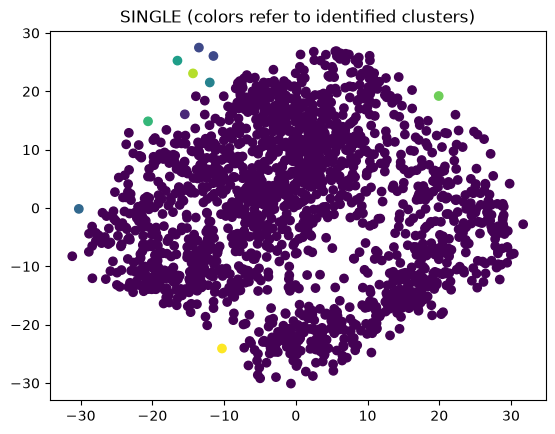

In [49]:
h = AgglomerativeClustering(linkage='single', n_clusters=10)
h.fit(X_2D)
plt.title("SINGLE (colors refer to identified clusters)")
plt.scatter(X_2D[:,0], X_2D[:,1],c=h.labels_)
plt.show()

**Excercise 3**

For the above four clustering results obtained for digits data, calculate the value of Adjusted Round Index (ARI) (`sklearn.metrics.adjusted_rand_score`) to evaluate the consistency of the obtained clustering and real labels.

In [50]:
linkage_methods = [
    'ward',
    'average',
    'complete',
    'single'
]

results = []

for linkage in linkage_methods:
    h = AgglomerativeClustering(linkage=linkage, n_clusters=10)
    h.fit(X_2D)

    score = metrics.adjusted_rand_score(y, h.labels_)
    results.append(score)

df = pd.DataFrame({
    "Linkage method": linkage_methods,
    "ARI": results})
display(df)

,Linkage method,ARI
0,ward,0.342762
1,average,0.348051
2,complete,0.303846
3,single,-0.000003


**Analysis of the obtained hierarchical structure of clustering**

It is possible to analyze the structure of clustering from attribute `children_`. The structure description will be analysed below for an example data set.

In [ ]:
x, y = make_blobs(n_samples = 20, n_features=2, centers=2)
h = AgglomerativeClustering(linkage='average', n_clusters=2)
h.fit(x)
plt.title("AVERAGE")
plt.scatter(x[:,0], x[:,1],c=h.labels_)
plt.show()
h.children_

The number of rows in `children_` array is one less than the number of elements in the data set. Subsequent rows correspond to iterations of the algorithm and they contain indices of joined elements. In our example there are 20 samples in the data set. If a value lower than 20 appears in the array, it means a sample of that index is linked in the given iteration. Values greater than 20 are indices of clusters that contain more than one sample. The index of a cluster created in a given iteration is equal to the index of the row increased by the number of elements in the set. For example, if in the third row of the aray we had [5,11], it would mean that in the third iteration samples 5 and 11 were combined into one cluster, which was assigned index 22 (2 + 20).

Hierarchical clustering has been also implemented in `scipy` package. In this case a dendrogram may be also drawn.

In [ ]:
from scipy.cluster import hierarchy
h2 = hierarchy.average(x)
den = hierarchy.dendrogram(h2, no_labels=True)
plt.show()

# DBSCAN algorithm

In [ ]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=2, min_samples=3)
dbscan.fit(X_2D) #X_2D - digits data previously transformed to 2D

plt.title("DBSCAN")
plt.scatter(X_2D[:,0], X_2D[:,1],c = dbscan.labels_)
plt.show()

The clustering results (labels) are saved in `dbscan.labels_`. Label value -1 indicates that the corresponding point has not been assigned to any cluster, which means it's an outlier.

**Excercise 4**

Perform DBSCAN clustering for your own dataset. Adjust the algorithm parameters (`eps`, `min_samples`) to obtain the desired number of clusters, i.e. the number you set while using `make_calssification` or `make_blobs` functions. Show the results on scatter plots.

# Clustering documents

We will be analyzing a collection of documents containing news from 20 newsgroups. To speed up the operation of the methods, we will limit to four selected categories (groups). Choose four categories by uncommenting them.

In [ ]:
import numpy as np
from sklearn.datasets import fetch_20newsgroups
categories = [
    #'alt.atheism',
    'comp.graphics',
    #'comp.os.ms-windows.misc',
    #'comp.sys.ibm.pc.hardware',
    #'comp.sys.mac.hardware',
    'comp.windows.x',
    #'misc.forsale',
    #'rec.autos',
    #'rec.motorcycles',
    #'rec.sport.baseball',
    #'rec.sport.hockey',
    #'sci.crypt',
    'sci.electronics',
    #'sci.med',
    'sci.space',
    #'soc.religion.christian',
    #'talk.politics.guns',
    #'talk.politics.mideast',
    #'talk.politics.misc',
    #'talk.religion.misc'
]
dataset = fetch_20newsgroups(subset='all', categories = categories, shuffle=True, random_state=42)

In [ ]:
print("The number of loaded documents is ", len(dataset.data))
print("They belong to one of ", len(dataset.target_names), " categories.")

Example news from the set is as follows:

In [ ]:
doc_number = 5
print("Example news from ", dataset.target_names[dataset.target[doc_number]])
dataset.data[doc_number]

Each document will be represented by a feature vector whose components are weights for the words considered in the analyzed set of documents. Class `TfidfVectorizer` is used to calcualate these feature vectors.

http://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html#sklearn.feature_extraction.text.TfidfVectorizer

The number of features describing documents may, in an extreme case, be equal to the number of all words appearing in all documents in the set.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer(max_df=0.5, min_df=2, max_features = None, stop_words='english')
X = vectorizer.fit_transform(dataset.data)
print("Number of documents: %d\nNumber of features: %d" %X.shape)

For a given document, the i-th component of a feature vector is the number of occurrences of the i-th word (feature) in this document multiplied by the idf coefficient, which depends on the total number of documents in the set and the number of documents containing the i-th word. A detailed description of determining these features can be found in the documentation
http://scikit-learn.org/stable/modules/feature_extraction.html.
The vector of idf values for all words (features) can be read as follows:


In [ ]:
vectorizer.idf_

The `get_feature_names` method allows you to read the names of all features, i.e. the words taken into account when analyzing a set of documents. They are sorted alphabetically.

In [ ]:
terms = vectorizer.get_feature_names_out()
terms[-20:-1]

**Excercise 5**


Choose one of the clustering methods you know, adjust its parameters and cluster documents from the given collection. Calculate the value of a selected cluster validity index.
1. for different number of clusters
2. for different number of features describing the documents (parameter `max_features`)

Adjust the values of the above two parameters (number of clusters, number of features) to obtain the best possible clustering (from the point of view of the selected cluster validity index). You may present the results of the analysis on plots.


**Excercise 6**

For each detected cluster, display 10 most significant features (words), i.e. 10 words with the highest values for the corresponding features. When analyzing the feature values, take into account only the cluster centers which are good representatives of each group.